# Fourier Series:
## Theory
In our discussion of inner products, we mentioned the Fourier Series Approximation. 
A Fourier series takes advantage of the fact that the functions $1,\sin(\pi x),\cos(\pi x), \sin(2 \pi x), \cos(2 \pi x),\dots, \sin(n \pi x), \cos(n \pi x)$ are orthogonal with respect to the inner product $<f,g> = \int_0^1 f(x) \cdot g(x) dx$. Thus to approximate a given function using a linear combination of sines and cosines, we can just use the standard formula for projecting a value $\vec{u}$ onto the orthogonal basis $\mathcal{B} = \{ \vec{v}_1, \vec{v}_2, \dots, \vec{v}_n\}$

$$ \text{proj}\vec{u}_\mathcal{B} = \frac{<\vec{u},\vec{v}_1>}{<\vec{v}_1,\vec{v}_1>} \vec{v}_1 + \frac{<\vec{u},\vec{v}_2>}{<\vec{v}_2,\vec{v}_2>} \vec{v}_2 + \frac{<\vec{u},\vec{v}_3>}{<\vec{v}_3,\vec{v}_3>} \vec{v}_3 + \dots + \frac{<\vec{u},\vec{v}_n>}{<\vec{v}_n,\vec{v}_n>} \vec{v}_n.$$

Applying this general equation to our orthogonal basis of sines and cosines we get the FOurier series approximation to function $f(x)$ as

$$f(x) \approx a_0 + a_1 \sin(\pi x) + b_1 \cos(\pi x) + a_2 \sin(2\pi x) + b_2 \cos(2\pi x) + \dots + a_n \sin(n \pi x) + b_n \cos(n \pi x).$$
Where the coefficinets are:

$$a_0 = \frac{<f(x),1>}{<1,1>} = \frac{\int_0^1 f(x) \cdot 1 dx}{\int_0^1 1^2 dx} = \int_0^1 f(x) dx$$

$$a_k = \frac{<f(x),\sin(k \pi x)>}{<\sin(k \pi x),\sin(k \pi x)>} = \frac{\int_0^1 f(x) \sin(k \pi x) dx}{\int_0^1 \sin^2(k \pi x)dx}= \frac{\int_0^1 f(x) \sin(k \pi x) dx}{1/2} = 2\int_0^1 f(x) \sin(k \pi x) dx$$

$$b_k = \frac{<f(x),\cos(k \pi x)>}{<\cos(k \pi x),\sin(k \pi x)>} = \frac{\int_0^1 f(x) \cos(k \pi x) dx}{\int_0^1 \cos^2(k \pi x)dx}= \frac{\int_0^1 f(x) \cos(k \pi x) dx}{1/2} = 2\int_0^1 f(x) \cos(k \pi x) dx$$

## Python Code
We will now implement code to evaluate a fourier series approximation to a given function.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import sympy as sp

In order to use the symbolic python (sympy) library we must first define a variable.

In [2]:
x = sp.Symbol('x')

Once a variable has been defined we can use  sympy to perform symbolic math calculations. Of particular interest to us here is the ability to integrate. Below is a line of code that evaluates $\int_2^3 5x^2 -3x + 2 dx$.

In [3]:
sp.integrate(5*x**2 - 3*x + 2,(x,2,3))

157/6

Now, for a given function of x, we can use the function below to evaluate as many fourier coefficients as we wish.

In [6]:
def Fourier(Func,maxK,display = True):
    #The display parameter can be set to false in order to avoid displaying the coefficient values.
    ao = sp.integrate(Func,(x,0,1))
    if display:
        print(f'a_0 = {ao}')
    ao = float(ao)
    avals = []
    bvals = []
    for k in range(1,maxK+1): #Range does not include endpoint so we add 1
        ak = 2* sp.integrate(Func*sp.sin(2*k*x*sp.pi),(x,0,1))
        if display:
            print(f'a_{k} = {ak}')
        bk = 2* sp.integrate(Func*sp.cos(2*k*x*sp.pi),(x,0,1))
        if display:
            print(f'b_{k} = {bk}')
        avals.append(float(ak))
        bvals.append(float(bk))
    return ao,avals,bvals
        

Let us test our code by evaluating the Fourier series approximation of the function $(x-\frac{1}{2})^3$.

In [28]:
Fourier((x-0.5)**3,4)

a_0 = 0
a_1 = -0.25/pi + 1.5/pi**3
b_1 = 0
a_2 = -0.125/pi + 0.1875/pi**3
b_2 = 0
a_3 = -0.0833333333333333/pi + 0.0555555555555556/pi**3
b_3 = -6.93889390390723e-18/pi**2
a_4 = -0.0625/pi + 0.0234375/pi**3
b_4 = 0


(0.0,
 [-0.031200169896148433,
  -0.03374157306674893,
  -0.0247340719356937,
  -0.019138472548208805],
 [0.0, 0.0, -7.030569435124824e-19, 0.0])

The code below, use the code above to plot both the true vlue of the funtion as well as its Fourier series approximation.

In [26]:
def PlotFourierApprox(Func,maxK):
    xvals = np.linspace(0,1,1000)
    f = sp.lambdify(x, Func, 'numpy')
    ytrue = np.array(f(xvals),dtype=float)
    ao,avals,bvals = Fourier(Func,maxK,False)
    yapprox = np.zeros_like(xvals)
    yapprox +=ao
    for k in range(1,maxK+1):
        ak = avals[k-1]
        bk = bvals[k-1]
        yapprox += ak*np.sin(2*np.pi*k*xvals)
        yapprox += bk*np.cos(2*np.pi*k*xvals)
    plt.plot(xvals,ytrue,'b-',label='True Function')
    plt.plot(xvals,yapprox,'r--',label='Fourier Approximation')
    plt.xlim([-0.1,1.1])
    plt.xlabel('x')
    plt.ylabel('y')
    plt.title(f'Fourier approximation of {Func}')
    plt.legend()
    plt.grid()
    plt.show()
    

Here are the results if $n=1.$ 

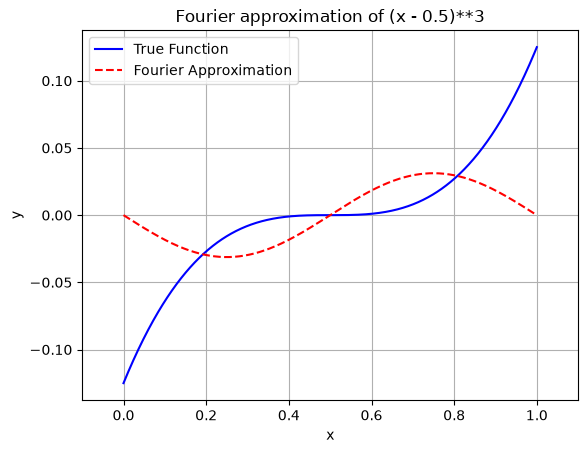

In [27]:
PlotFourierApprox((x-0.5)**3,1)

For $n=3$

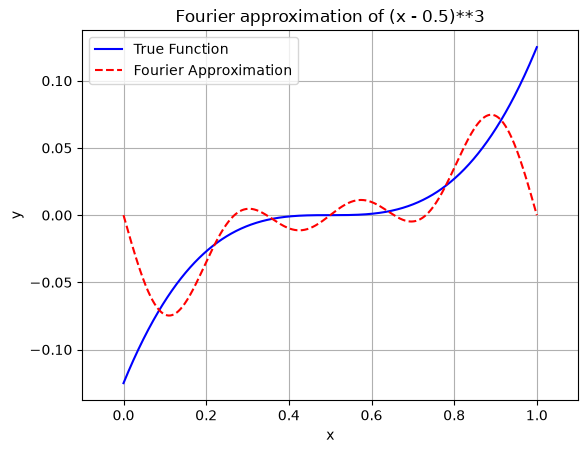

In [29]:
PlotFourierApprox((x-0.5)**3,3)

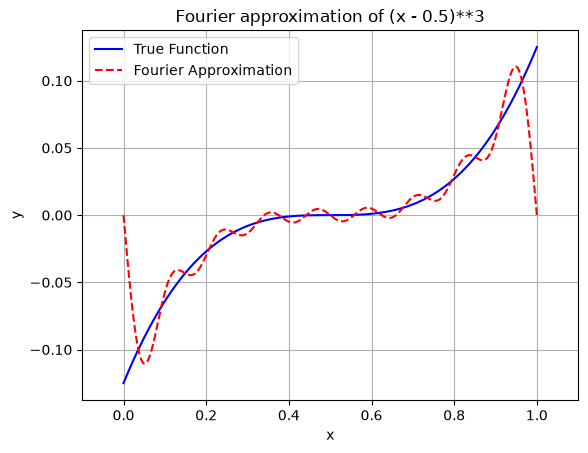

In [30]:
PlotFourierApprox((x-0.5)**3,8)

As you can see, using more and more terms leads to better and better agreement between the true and approximate vlaues.